# Fit-Modes Method Comparison Curves

This notebook assembles the paper-figure curve preview for the OASIS rank-9
case and LungCT cases 01/08.

Panel A compares image-registration similarity curves. IDIR uses the newly
rerun matched diagnostic metric every 10 epochs; SINR/DirectCP use their
per-epoch matched data-loss histories. LungCT DirectCP 4-stage registration
uses the existing posthoc `finest_data_loss` diagnostic, not stage-domain
training loss. Panel B compares target-field fitting MSE curves against the
SITReg target for OASIS and the pTVReg target for LungCT; LungCT DirectCP
4-stage field fitting uses the rerun posthoc finest-domain MSE diagnostics.


## Figure Message

The field-fitting objective is easy for local-control spline methods: DirectCP
fits the target fields very well on all three cases. Registration tells a
different story. OASIS is comparatively forgiving, LungCT case01 is easier, and
LungCT case08 exposes the need for a multistage optimization path rather than
a single cps4 spline solve.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

pd.options.display.max_columns = 80
pd.options.display.max_colwidth = 120

candidates = [
    Path.cwd(),
    Path("/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure"),
    Path("experiments/2026-06-26_fit_modes_paper_figure").resolve(),
]
for candidate in candidates:
    if (candidate / "fit_modes_method_comparison.py").exists():
        REVIEW_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate fit_modes_method_comparison.py")

sys.path.insert(0, str(REVIEW_ROOT))
print(REVIEW_ROOT)


/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure


In [2]:
from fit_modes_method_comparison import (
    build_outputs,
    load_curves,
    make_main_figure,
    save_main_figure,
    selected_runs,
    curve_summary,
)


## Selected Runs

One LR is selected per method/case/task. Registration IDIR is fixed to
`lr=1e-4` because that is the matched-metric rerun. Other registration LRs are
selected by final label metric: Dice for OASIS and native-crop snap TRE for
LungCT, except LungCT DirectCP 4-stage, which is fixed to the existing
`lr=1e-2` finest-domain diagnostic run. Field-fitting LRs are selected by
objective target-field MSE.


In [3]:
selection = selected_runs()
display(selection.drop(columns=["run_dir"]))
selection.to_csv(REVIEW_ROOT / "fit_modes_method_comparison_selected_runs.csv", index=False)


,case,task,method,lr,selection_metric,selection_value,curve_metric
0,OASIS rank-9,SITReg field fit,IDIR,0.0001,min objective field MSE,1.385626e-05,masked normalized-grid MSE
1,OASIS rank-9,SITReg field fit,SINR cps4,0.0010,min objective field MSE,8.539376e-06,masked normalized-grid MSE
2,OASIS rank-9,SITReg field fit,DirectCP cps4,0.0100,min objective field MSE,7.776494e-06,masked normalized-grid MSE
3,OASIS rank-9,registration,IDIR,0.0001,fixed to matched-eval rerun,8.110368e-01,global NCC loss
4,OASIS rank-9,registration,SINR cps4,0.0001,max final Dice among completed LR sweep,8.295876e-01,global NCC loss
5,OASIS rank-9,registration,DirectCP cps4,0.0010,max final Dice among completed LR sweep,8.267911e-01,global NCC loss
6,LungCT case01,pTVReg field fit,IDIR,0.0010,min objective field MSE,2.511078e-06,masked normalized-grid MSE
7,LungCT case01,pTVReg field fit,SINR cps4,0.0010,min objective field MSE,2.451089e-07,masked normalized-grid MSE
8,LungCT case01,pTVReg field fit,DirectCP cps4,0.0100,min objective field MSE,2.846273e-08,masked normalized-grid MSE
9,LungCT case01,pTVReg field fit,DirectCP 4stage cps4,0.0100,fixed to rerun finest-domain diagnostic,2.846052e-08,masked normalized-grid MSE


## Curve Inputs

IDIR registration curves have 251 points: epoch 1 plus every 10 epochs through
2500. Other registration histories are per-epoch curves. LungCT DirectCP
4-stage registration uses `finest_data_loss`. LungCT DirectCP 4-stage
field-fitting also uses `finest_data_loss` from the rerun diagnostic histories:
coarse stages are evaluated every 50 epochs, and the final full-resolution
stage is evaluated every epoch.


In [4]:
reg_curves, field_curves = load_curves(selection)
summary = pd.concat(
    [
        curve_summary(reg_curves).assign(curve_group="registration"),
        curve_summary(field_curves).assign(curve_group="field_fit"),
    ],
    ignore_index=True,
)
display(summary.drop(columns=["source"]))
summary.to_csv(REVIEW_ROOT / "fit_modes_method_comparison_curve_summary.csv", index=False)


,case,task,method,lr,points,epoch_min,epoch_max,value_start,value_end,note,curve_group
0,OASIS rank-9,registration,IDIR,0.0001,251,1.0,2500.0,-0.884194,-9.750215e-01,IDIR matched global NCC evaluated every 10 epochs.,registration
1,OASIS rank-9,registration,SINR cps4,0.0001,2500,1.0,2500.0,-0.839242,-9.910164e-01,Per-epoch SINR global NCC data loss.,registration
2,OASIS rank-9,registration,DirectCP cps4,0.0010,2500,1.0,2500.0,-0.900681,-9.911135e-01,Per-epoch SINR global NCC data loss.,registration
3,LungCT case01,registration,IDIR,0.0001,251,1.0,2500.0,5.538059,2.817244e+00,IDIR matched pTV LCC evaluated every 10 epochs.,registration
4,LungCT case01,registration,SINR cps4,0.0010,2500,1.0,2500.0,5.278737,2.627739e+00,Per-epoch pTV LCC data loss.,registration
5,LungCT case01,registration,DirectCP cps4,0.0100,2500,1.0,2500.0,3.932446,2.634305e+00,Per-epoch pTV LCC data loss.,registration
6,LungCT case01,registration,DirectCP 4stage cps4,0.0100,2500,1.0,2500.0,3.932446,2.613967e+00,Posthoc finest-domain pTV LCC diagnostic; training still used stage-domain loss.,registration
7,LungCT case08,registration,IDIR,0.0001,251,1.0,2500.0,9.890514,5.032755e+00,IDIR matched pTV LCC evaluated every 10 epochs.,registration
8,LungCT case08,registration,SINR cps4,0.0010,2500,1.0,2500.0,9.646268,5.174368e+00,Per-epoch pTV LCC data loss.,registration
9,LungCT case08,registration,DirectCP cps4,0.0100,2500,1.0,2500.0,9.068019,4.995810e+00,Per-epoch pTV LCC data loss.,registration


## Main Comparison Figure

The display applies a centered rolling median only for readability. Set
`smooth=False` in `make_main_figure(...)` below to inspect unsmoothed curves.
The saved PDF/PNG use the same figure shown inline.


- `pdf`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison_curves.pdf`
- `png`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison_curves.png`

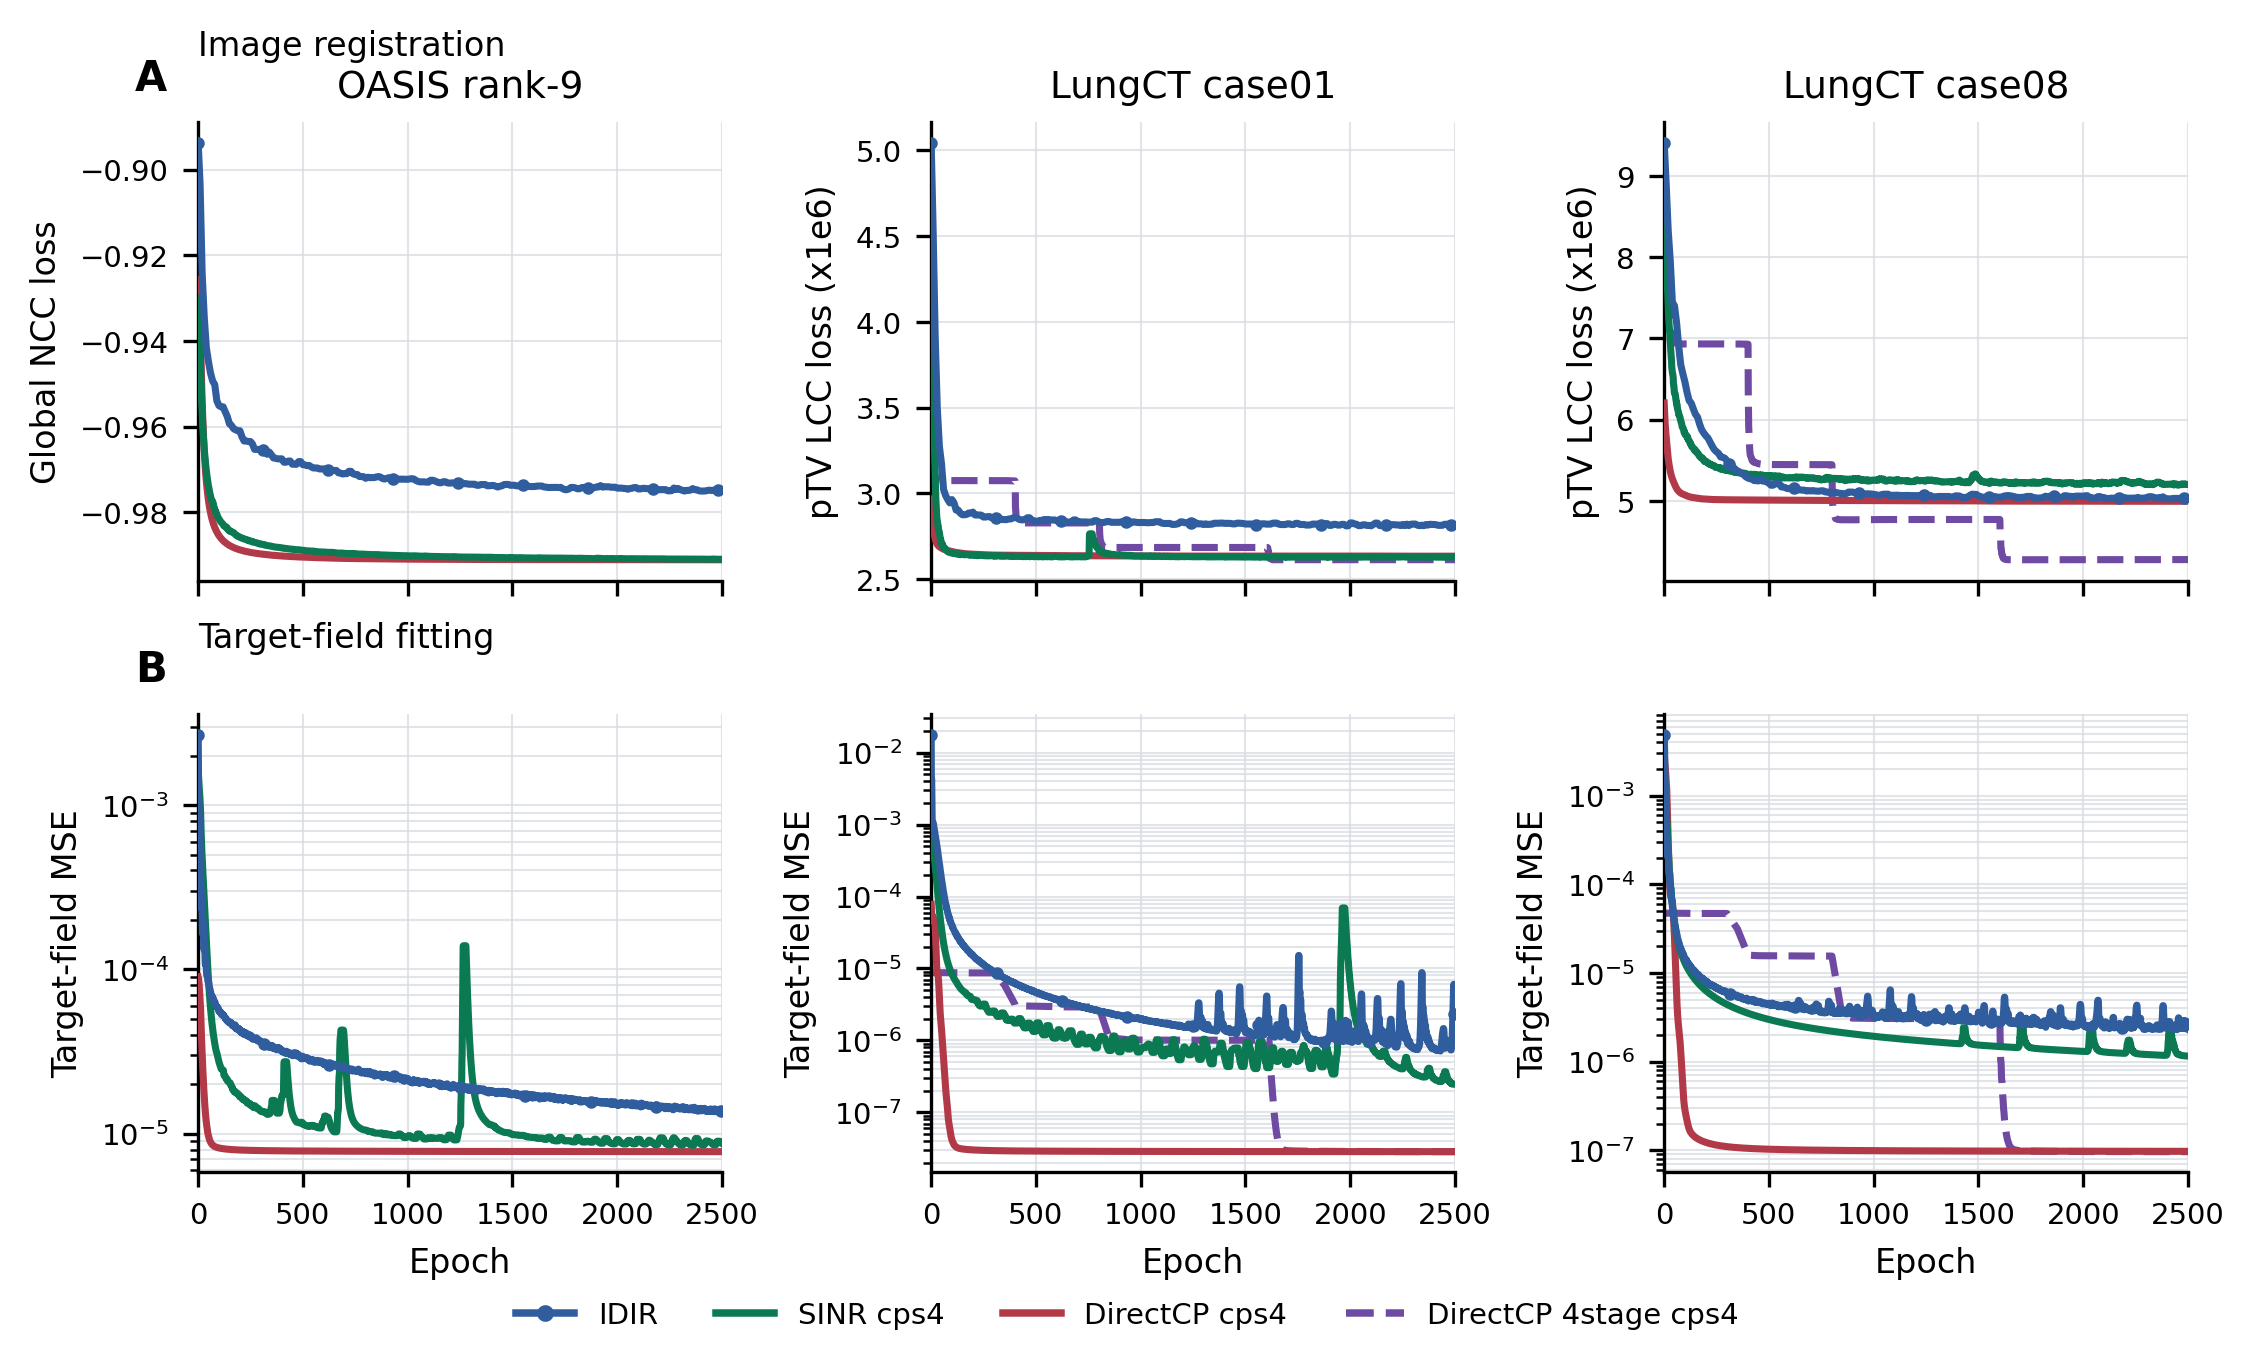

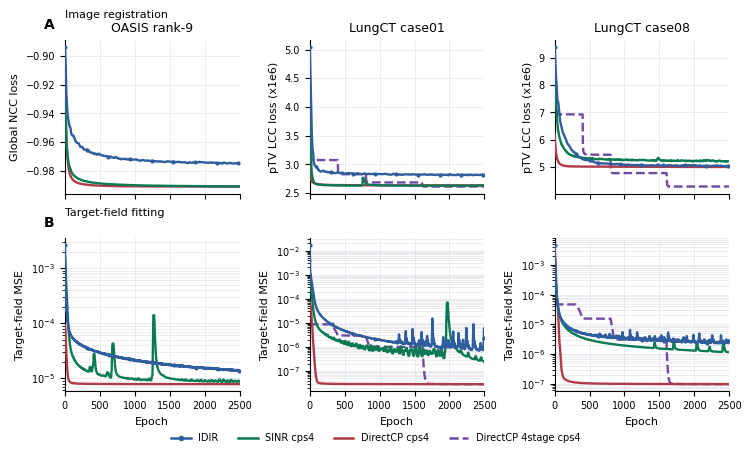

In [5]:
fig = make_main_figure(reg_curves, field_curves, smooth=True)
outputs = save_main_figure(fig)
display(Markdown("\n".join([f"- `{name}`: `{path}`" for name, path in outputs.items()])))
display(Image(filename=str(outputs["png"])))


## Output Files

The notebook writes:

- `fit_modes_method_comparison_curves.pdf`
- `fit_modes_method_comparison_curves.png`
- `fit_modes_method_comparison_selected_runs.csv`
- `fit_modes_method_comparison_curve_summary.csv`
